In [57]:
%pip install --upgrade statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 2.8 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/11.3 MB 3.2 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/11.3 MB 2.9 MB/s eta 0:00:04
   -------- ------------------------------- 2.4/11.3 MB 3.0 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/11.3 MB 3.1 MB/s eta 0:00:03
   ------------- -------------------------- 3.9/11.3 MB 3.2 MB/s eta 0:00:03
   ---------------- ----------------------- 4.7/11.3 MB 3.3 MB/s eta 0:00:02
   ------------------ --------------------- 5.2/11.3 MB 3.3 MB/s eta 0:00:02
   --------------------- ------------------ 6.0/11.3 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.3 MB 3.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.3/11.3 MB 3.3 MB/s eta 0:00:02
   --------------------------- ------------ 7.9/11.3 MB 3.2 MB/s eta 0:00:02
   ---

  You can safely remove it manually.


In [1]:
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

import warnings

In [3]:
#Set seed for reproducability
np.random.seed(2026)

# Reading the data

In [5]:
#Read data
eoh = pd.read_csv("Data/eoh_data.csv", skiprows = [1,2], index_col= 0)
npn = pd.read_csv("Data/npn_data.csv", skiprows = [1,2], index_col= 0)
prx = pd.read_csv("Data/prx_data.csv", skiprows = [1,2], index_col= 0)

#Set date index
eoh.index.name = "Date"
npn.index.name = "Date"
prx.index.name = "Date"

eoh.index = pd.to_datetime(eoh.index)
npn.index = pd.to_datetime(npn.index)
prx.index = pd.to_datetime(prx.index)

eoh = eoh.sort_index()
npn = npn.sort_index()
prx = prx.sort_index()

In [7]:
for name, df in {
    "Naspers": npn,
    "Prosus": prx,
    "EOH": eoh
}.items():

    print(name)
    print("Duplicate dates:", df.index.duplicated().sum())
    print("Missing dates:", df.index.isna().sum())

Naspers
Duplicate dates: 0
Missing dates: 0
Prosus
Duplicate dates: 0
Missing dates: 0
EOH
Duplicate dates: 0
Missing dates: 0


In [9]:
npn.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1499 entries, 2020-01-02 to 2025-12-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1499 non-null   float64
 1   High    1499 non-null   float64
 2   Low     1499 non-null   float64
 3   Open    1499 non-null   float64
 4   Volume  1499 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 70.3 KB


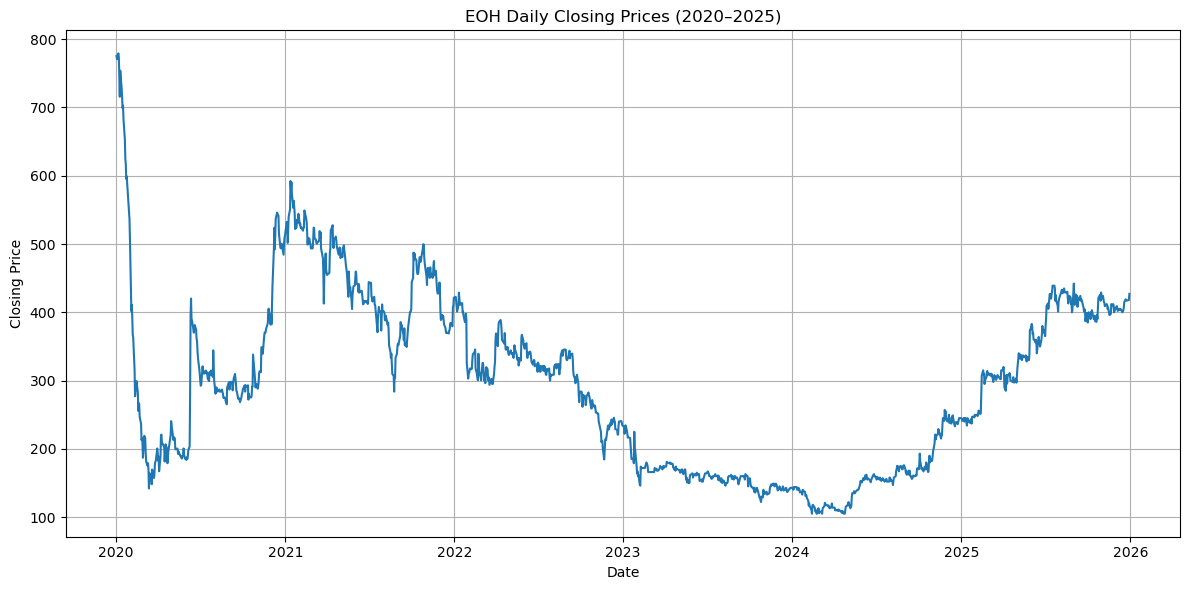

In [11]:
#EOH Holdings Plot
plt.figure(figsize=(12, 6))
plt.plot(eoh.index, eoh["Close"])

plt.title("EOH Daily Closing Prices (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.tight_layout()
plt.show()

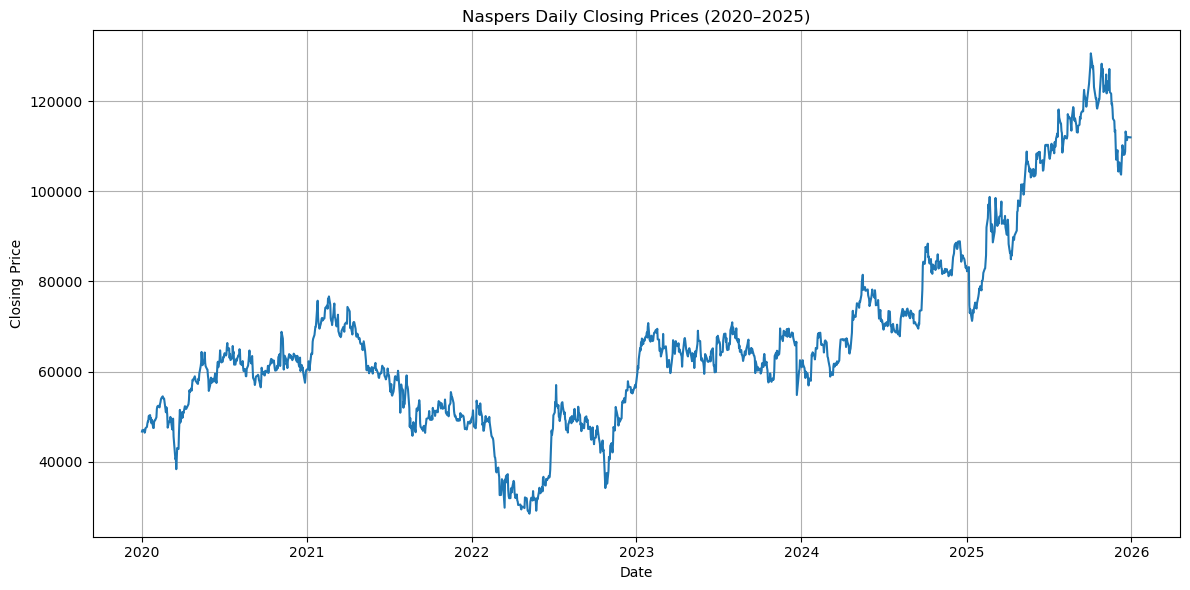

In [13]:
#Naspers Plot
plt.figure(figsize=(12, 6))
plt.plot(npn.index, npn["Close"])

plt.title("Naspers Daily Closing Prices (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.tight_layout()
plt.show()

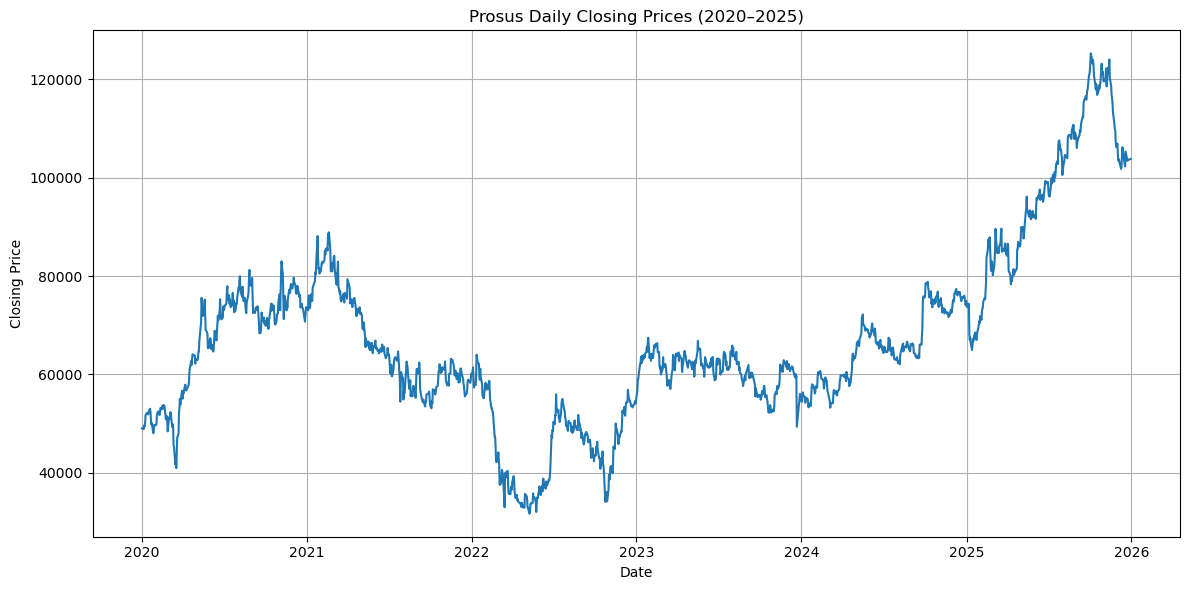

In [15]:
#Prosus Plot
plt.figure(figsize=(12, 6))
plt.plot(prx.index, prx["Close"])

plt.title("Prosus Daily Closing Prices (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.tight_layout()
plt.show()

# Data Preprocessing

In [17]:
#Technical indicator function
def technical_indicators(df):
    df = df.copy()

    #Simple Moving Average 10, 20
    df["SMA_10"] = ta.sma(df["Close"], length=10)
    df["SMA_20"] = ta.sma(df["Close"], length=20)

    #Exponential Moving Average 10, 20
    df["EMA_10"] = ta.ema(df["Close"], length=10)
    df["EMA_20"] = ta.ema(df["Close"], length=20)

    #Relative Strength Index
    df["RSI_14"] = ta.rsi(df["Close"], length=14)

    #Moving Average Convergence Divergence
    macd = ta.macd(df["Close"], fast=12, slow=26, signal=9)
    if macd is not None:
        df = pd.concat([df, macd], axis=1)

    #Rate of Change 10
    df["ROC_10"] = ta.roc(df["Close"], length=10)
    return df


#Add technical indicators to each dataset
eoh = technical_indicators(eoh)
npn = technical_indicators(npn)
prx = technical_indicators(prx)

In [19]:
eoh.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1499 entries, 2020-01-02 to 2025-12-30
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close          1499 non-null   float64
 1   High           1499 non-null   float64
 2   Low            1499 non-null   float64
 3   Open           1499 non-null   float64
 4   Volume         1499 non-null   int64  
 5   SMA_10         1490 non-null   float64
 6   SMA_20         1480 non-null   float64
 7   EMA_10         1490 non-null   float64
 8   EMA_20         1480 non-null   float64
 9   RSI_14         1498 non-null   float64
 10  MACD_12_26_9   1474 non-null   float64
 11  MACDh_12_26_9  1466 non-null   float64
 12  MACDs_12_26_9  1466 non-null   float64
 13  ROC_10         1489 non-null   float64
dtypes: float64(13), int64(1)
memory usage: 208.0 KB


In [21]:
#Create target variable
def create_target(df):
    df = df.copy()
    
    future_close = df["Close"].shift(-1)

    #Create the target
    df["Target"] = np.where(
        future_close.isna(),
        np.nan,
        (future_close > df["Close"]).astype(int)
    )
    return df

eoh = create_target(eoh)
npn = create_target(npn)
prx = create_target(prx)

In [23]:
#List of Features
features = [
    "Open", "High", "Low", "Close", "Volume",
    "SMA_10", "SMA_20", "EMA_10", "EMA_20", "RSI_14", 
    "MACD_12_26_9", "MACDh_12_26_9", "MACDs_12_26_9", "ROC_10"
    ]

In [25]:
# Remove Missing Values
def remove_na(df):
    df = df.copy()

    # Remove rows missing any required features or target
    df = df.dropna(subset=features + ["Target"])

    # Ensure target is an integer
    df["Target"] = df["Target"].astype(int)
    
    return df

eoh = remove_na(eoh)
npn = remove_na(npn)
prx = remove_na(prx)

In [27]:
eoh.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1465 entries, 2020-02-18 to 2025-12-29
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close          1465 non-null   float64
 1   High           1465 non-null   float64
 2   Low            1465 non-null   float64
 3   Open           1465 non-null   float64
 4   Volume         1465 non-null   int64  
 5   SMA_10         1465 non-null   float64
 6   SMA_20         1465 non-null   float64
 7   EMA_10         1465 non-null   float64
 8   EMA_20         1465 non-null   float64
 9   RSI_14         1465 non-null   float64
 10  MACD_12_26_9   1465 non-null   float64
 11  MACDh_12_26_9  1465 non-null   float64
 12  MACDs_12_26_9  1465 non-null   float64
 13  ROC_10         1465 non-null   float64
 14  Target         1465 non-null   int32  
dtypes: float64(13), int32(1), int64(1)
memory usage: 177.4 KB


In [29]:
#Put datasets into dictionary for ease of access
datasets = {
    "Naspers": npn,
    "Prosus": prx,
    "EOH": eoh
}

In [31]:
#Train Test Split 80-20
def split_data(df, features, target="Target"):
    df = df.sort_index()

    X = df[features]
    y = df[target]

    split_index = int(len(df) * 0.8)

    X_train = X.iloc[:split_index-1]
    X_test = X.iloc[split_index:]

    y_train = y.iloc[:split_index-1]
    y_test = y.iloc[split_index:]

    return X_train, X_test, y_train, y_test

splits = {}

#Apply function to datasets
for name, df in datasets.items():
    X_train, X_test, y_train, y_test = split_data(df, features)

    splits[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }


In [33]:
def select_features(X_train, y_train, method="none", k=8):
    # use every feature
    if method == "none":
        return X_train.columns.tolist()

    #Random Forest feature importance
    elif method == "rf":
        selector = RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        )

        selector.fit(X_train, y_train)

        scores = pd.Series(
            selector.feature_importances_,
            index=X_train.columns
        )

    #Pearson correlation
    elif method == "pearson":
        scores = X_train.corrwith(y_train).abs().dropna()

    else:
        raise ValueError("Unknown feature selection method")

    # Return the k highest-ranked features
    selected = scores.sort_values(ascending=False).head(k)

    return selected.index.tolist()


In [35]:
methods = ["none", "pearson", "rf"]

selected_data = {}

#Apply feature selection
for name, split in splits.items():
    selected_data[name] = {}

    for method in methods:
        selected_features = select_features(
            split["X_train"],
            split["y_train"],
            method=method,
            k=8
        )

        selected_data[name][method] = {
            "features": selected_features,
            "X_train": split["X_train"][selected_features],
            "X_test": split["X_test"][selected_features],
            "y_train": split["y_train"],
            "y_test": split["y_test"]
        }

In [37]:
for stock, methods_data in selected_data.items():
    print(f"\n{'='*50}")
    print(f"Stock: {stock}")
    print(f"{'='*50}")

    for method, data in methods_data.items():
        print(f"\nMethod: {method}")
        print(f"Number of features: {len(data['features'])}")
        print(f"Selected features: {data['features']}")


Stock: Naspers

Method: none
Number of features: 14
Selected features: ['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_10', 'SMA_20', 'EMA_10', 'EMA_20', 'RSI_14', 'MACD_12_26_9', 'MACDh_12_26_9', 'MACDs_12_26_9', 'ROC_10']

Method: pearson
Number of features: 8
Selected features: ['MACDh_12_26_9', 'ROC_10', 'Volume', 'RSI_14', 'MACDs_12_26_9', 'SMA_20', 'SMA_10', 'EMA_20']

Method: rf
Number of features: 8
Selected features: ['MACDh_12_26_9', 'RSI_14', 'Volume', 'ROC_10', 'MACDs_12_26_9', 'MACD_12_26_9', 'Low', 'Close']

Stock: Prosus

Method: none
Number of features: 14
Selected features: ['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_10', 'SMA_20', 'EMA_10', 'EMA_20', 'RSI_14', 'MACD_12_26_9', 'MACDh_12_26_9', 'MACDs_12_26_9', 'ROC_10']

Method: pearson
Number of features: 8
Selected features: ['ROC_10', 'MACDh_12_26_9', 'RSI_14', 'Volume', 'SMA_20', 'SMA_10', 'EMA_20', 'EMA_10']

Method: rf
Number of features: 8
Selected features: ['Volume', 'RSI_14', 'ROC_10', 'MACDs_12_26_9', '

# ARIMA Model training

In [39]:
arima_models = {}

train_close_prices = {}
test_close_prices = {}

for name, split in splits.items():
    train_close_prices[name] = split["X_train"]["Close"]
    test_close_prices[name] = split["X_test"]["Close"]

In [41]:
#Augmented Dickey Fueller test
def adf_test(series):
    series = series.dropna().astype(float)
    result = adfuller(series, result_object = True)

    print("ADF statistic:", result[0])
    print("p-value:", result[1])

    if result[1] < 0.05:
        print("The series is stationary.")
    else:
        print("The series is non-stationary.")

In [43]:
for name, close in train_close_prices.items():
    print(f"\n{name} - Original series")
    adf_test(close)

    print(f"\n{name} - First difference")
    adf_test(close.diff().dropna())


Naspers - Original series
ADF statistic: -1.7811889107266359
p-value: 0.38984005508093467
The series is non-stationary.

Naspers - First difference
ADF statistic: -25.790788630647118
p-value: 0.0
The series is stationary.

Prosus - Original series
ADF statistic: -1.9583459066840203
p-value: 0.30513013857627724
The series is non-stationary.

Prosus - First difference
ADF statistic: -25.703509582854682
p-value: 0.0
The series is stationary.

EOH - Original series
ADF statistic: -1.2715668461150291
p-value: 0.6420780754940558
The series is non-stationary.

EOH - First difference
ADF statistic: -12.218860879291245
p-value: 1.119227199743285e-22
The series is stationary.


d = 1 for all

In [45]:
def find_aic(close, max_p=3, d=1, max_q=3):

    close = close.dropna().astype(float).reset_index(drop=True)
    results = []

    for p in range(max_p + 1):
        for q in range(max_q + 1):

            try:
                model = ARIMA(
                    close,
                    order=(p, d, q)
                )

                fitted_model = model.fit()

                converged = fitted_model.mle_retvals.get(
                    "converged", False
                )

                results.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": fitted_model.aic,
                    "Converged": converged
                })

            except Exception as e:
                print(f"ARIMA({p},{d},{q}) failed: {e}")

    results = pd.DataFrame(results)

    return results.sort_values("AIC").reset_index(drop=True)

In [47]:
aic_results = {}

for name, close in train_close_prices.items():

    results_df = find_aic(
        close,
        max_p=3,
        d=1,
        max_q=3
    )

    aic_results[name] = results_df

    print(f"\n{name}")
    print(results_df.head(5).to_string(index=False))

    best = results_df.iloc[0]

    print(
        f"Best ARIMA order: "
        f"({int(best['p'])}, {int(best['d'])}, {int(best['q'])})"
    )

D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to


Naspers
 p  d  q          AIC  Converged
 1  1  1 20438.386678       True
 0  1  0 20439.100086       True
 1  1  2 20439.918443       True
 2  1  1 20439.926627       True
 0  1  2 20440.292948       True
Best ARIMA order: (1, 1, 1)


D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params



Prosus
 p  d  q          AIC  Converged
 0  1  0 20419.166450       True
 1  1  1 20420.282176       True
 0  1  2 20420.989465       True
 1  1  2 20421.071881       True
 2  1  1 20421.083067       True
Best ARIMA order: (0, 1, 0)


D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
D:\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using 


EOH
 p  d  q         AIC  Converged
 2  1  2 8881.244946       True
 3  1  2 8881.430525       True
 0  1  1 8889.225106       True
 1  1  0 8889.655048       True
 2  1  1 8890.396154       True
Best ARIMA order: (2, 1, 2)


In [49]:
arima_models = {}
best_orders = {}

for name, results_df in aic_results.items():

    best = results_df.iloc[0]

    order = (
        int(best["p"]),
        int(best["d"]),
        int(best["q"])
    )

    close = train_close_prices[name].astype(float).reset_index(drop=True)

    model = ARIMA(close, order=order)
    fitted_model = model.fit()

    arima_models[name] = fitted_model
    best_orders[name] = order

    print(f"{name}: ARIMA{order}")
    print(f"AIC: {fitted_model.aic}")

Naspers: ARIMA(1, 1, 1)
AIC: 20438.38667814155
Prosus: ARIMA(0, 1, 0)
AIC: 20419.16645004648
EOH: ARIMA(2, 1, 2)
AIC: 8881.244946242241


In [51]:
def arima_predictions(df, train_close, order):

    df = df.sort_index()

    # Get the test data
    test_data = df.iloc[len(train_close):]

    # Fit model using training data
    model = ARIMA(
        train_close.astype(float).reset_index(drop=True),
        order=order
    )

    fitted_model = model.fit()

    predictions = []
    actual = []

    for date, row in test_data.iterrows():

        current_close = float(row["Close"])

        # Update model with the current observed closing price
        fitted_model = fitted_model.append(
            [current_close],
            refit=False
        )

        # Forecast the next closing price
        forecast = fitted_model.forecast(steps=1)

        predicted_close = float(np.asarray(forecast)[0])

        # Convert forecast into binary classification
        predicted_direction = int(
            predicted_close > current_close
        )

        predictions.append(predicted_direction)
        actual.append(int(row["Target"]))

    results = pd.DataFrame({
        "Actual": actual,
        "Predicted": predictions
    }, index=test_data.index)

    return fitted_model, results

In [57]:
arima_results = {}

for name, df in datasets.items():

    fitted_model, results = arima_predictions(
        df,
        train_close_prices[name],
        best_orders[name]
    )

    arima_results[name] = results

    print(f"\n{name} ARIMA Results")

    print("Accuracy:",
          accuracy_score(results["Actual"], results["Predicted"]))

    print("Precision:",
          precision_score(results["Actual"], results["Predicted"], zero_division=0))

    print("Recall:",
          recall_score(results["Actual"], results["Predicted"], zero_division=0))

    print("F1-Score:",
          f1_score(results["Actual"], results["Predicted"], zero_division=0))

    print("\nClassification Report:")
    print(classification_report(
        results["Actual"],
        results["Predicted"],
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        results["Actual"],
        results["Predicted"]
    ))


Naspers ARIMA Results
Accuracy: 0.5238095238095238
Precision: 0.5873015873015873
Recall: 0.4567901234567901
F1-Score: 0.5138888888888888

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.61      0.53       132
           1       0.59      0.46      0.51       162

    accuracy                           0.52       294
   macro avg       0.53      0.53      0.52       294
weighted avg       0.54      0.52      0.52       294


Confusion Matrix:
[[80 52]
 [88 74]]

Prosus ARIMA Results
Accuracy: 0.445578231292517
Precision: 0.0
Recall: 0.0
F1-Score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.45      1.00      0.62       131
           1       0.00      0.00      0.00       163

    accuracy                           0.45       294
   macro avg       0.22      0.50      0.31       294
weighted avg       0.20      0.45      0.27       294


Confusion Matrix:
[[131   0]
 

# Logistic Regression

In [59]:
logistic_models = {}
logistic_results = {}

for name in selected_data:

    logistic_models[name] = {}
    logistic_results[name] = {}

    for method in methods:

        data = selected_data[name][method]

        # Initialise scaler
        scaler = StandardScaler()

        # Fit scaler on training data
        X_train_scaled = scaler.fit_transform(data["X_train"])

        # Transform testing data
        X_test_scaled = scaler.transform(data["X_test"])

        # Initialise Logistic Regression
        model = LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight = "balanced"
        )

        # Train model
        model.fit(X_train_scaled, data["y_train"])

        # Make predictions
        predictions = model.predict(X_test_scaled)

        # Store model and scaler
        logistic_models[name][method] = {
            "model": model,
            "scaler": scaler
        }

        # Store predictions
        logistic_results[name][method] = pd.DataFrame({
            "Actual": data["y_test"],
            "Predicted": predictions
        }, index=data["y_test"].index)

        print(f"\n{name} - {method}")

        print("Accuracy:",
              accuracy_score(data["y_test"], predictions))

        print("Precision:",
              precision_score(data["y_test"], predictions,
                              zero_division=0))

        print("Recall:",
              recall_score(data["y_test"], predictions,
                           zero_division=0))

        print("F1-score:",
              f1_score(data["y_test"], predictions,
                       zero_division=0))


Naspers - none
Accuracy: 0.4778156996587031
Precision: 0.5317460317460317
Recall: 0.4161490683229814
F1-score: 0.46689895470383275

Naspers - pearson
Accuracy: 0.4880546075085324
Precision: 0.5407407407407407
Recall: 0.453416149068323
F1-score: 0.49324324324324326

Naspers - rf
Accuracy: 0.4812286689419795
Precision: 0.5365853658536586
Recall: 0.40993788819875776
F1-score: 0.4647887323943662

Prosus - none
Accuracy: 0.4812286689419795
Precision: 0.5235849056603774
Recall: 0.6851851851851852
F1-score: 0.5935828877005348

Prosus - pearson
Accuracy: 0.5119453924914675
Precision: 0.5411255411255411
Recall: 0.7716049382716049
F1-score: 0.6361323155216285

Prosus - rf
Accuracy: 0.5017064846416383
Precision: 0.5370370370370371
Recall: 0.7160493827160493
F1-score: 0.6137566137566137

EOH - none
Accuracy: 0.5767918088737202
Precision: 0.6021505376344086
Recall: 0.3916083916083916
F1-score: 0.4745762711864407

EOH - pearson
Accuracy: 0.5733788395904437
Precision: 0.59375
Recall: 0.3986013986013

In [61]:
for name in logistic_results:
    for method in methods:
        results = logistic_results[name][method]

        print(f"\n{name} - {method}")

        cm = confusion_matrix(
            results["Actual"],
            results["Predicted"]
        )

        print(cm)


Naspers - none
[[73 59]
 [94 67]]

Naspers - pearson
[[70 62]
 [88 73]]

Naspers - rf
[[75 57]
 [95 66]]

Prosus - none
[[ 30 101]
 [ 51 111]]

Prosus - pearson
[[ 25 106]
 [ 37 125]]

Prosus - rf
[[ 31 100]
 [ 46 116]]

EOH - none
[[113  37]
 [ 87  56]]

EOH - pearson
[[111  39]
 [ 86  57]]

EOH - rf
[[99 51]
 [80 63]]


In [63]:
for name in logistic_results:
    for method in methods:
        results = logistic_results[name][method]

        print(f"\n{name} - {method}")

        print(classification_report(
            results["Actual"],
            results["Predicted"],
            zero_division=0
        ))


Naspers - none
              precision    recall  f1-score   support

           0       0.44      0.55      0.49       132
           1       0.53      0.42      0.47       161

    accuracy                           0.48       293
   macro avg       0.48      0.48      0.48       293
weighted avg       0.49      0.48      0.48       293


Naspers - pearson
              precision    recall  f1-score   support

           0       0.44      0.53      0.48       132
           1       0.54      0.45      0.49       161

    accuracy                           0.49       293
   macro avg       0.49      0.49      0.49       293
weighted avg       0.50      0.49      0.49       293


Naspers - rf
              precision    recall  f1-score   support

           0       0.44      0.57      0.50       132
           1       0.54      0.41      0.46       161

    accuracy                           0.48       293
   macro avg       0.49      0.49      0.48       293
weighted avg       0.49  

# Support Vector Machines

In [65]:
svm_models = {}
svm_results = {}

for name in selected_data:
    svm_models[name] = {}
    svm_results[name] = {}
    
    for method in methods:
        data = selected_data[name][method]

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            data["X_train"]
        )

        X_test_scaled = scaler.transform(
            data["X_test"]
        )

        model = SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced"
        )

        model.fit(
            X_train_scaled,
            data["y_train"]
        )

        predictions = model.predict(X_test_scaled)

        svm_models[name][method] = {
            "model": model,
            "scaler": scaler
        }

        svm_results[name][method] = pd.DataFrame({
            "Actual": data["y_test"],
            "Predicted": predictions
        }, index=data["y_test"].index)

        print(f"\n{name} - {method}")

        print("Accuracy:", accuracy_score(data["y_test"], predictions))

        print("Precision:", precision_score(data["y_test"], predictions, zero_division=0))

        print("Recall:", recall_score(data["y_test"], predictions, zero_division=0))

        print("F1-score:", f1_score(data["y_test"], predictions, zero_division=0))


Naspers - none
Accuracy: 0.5119453924914675
Precision: 0.5473684210526316
Recall: 0.6459627329192547
F1-score: 0.5925925925925926

Naspers - pearson
Accuracy: 0.46075085324232085
Precision: 0.5189873417721519
Recall: 0.2546583850931677
F1-score: 0.3416666666666667

Naspers - rf
Accuracy: 0.46757679180887374
Precision: 0.6086956521739131
Recall: 0.08695652173913043
F1-score: 0.15217391304347827

Prosus - none
Accuracy: 0.45733788395904434
Precision: 0.5154639175257731
Recall: 0.30864197530864196
F1-score: 0.3861003861003861

Prosus - pearson
Accuracy: 0.4948805460750853
Precision: 0.5291666666666667
Recall: 0.7839506172839507
F1-score: 0.6318407960199005

Prosus - rf
Accuracy: 0.5017064846416383
Precision: 0.5615384615384615
Recall: 0.4506172839506173
F1-score: 0.5

EOH - none
Accuracy: 0.5255972696245734
Precision: 0.5105263157894737
Recall: 0.6783216783216783
F1-score: 0.5825825825825826

EOH - pearson
Accuracy: 0.49146757679180886
Precision: 0.4861111111111111
Recall: 0.734265734265

In [67]:
for name in svm_results:
    for method in methods:
        results = svm_results[name][method]

        cm = confusion_matrix(
            results["Actual"],
            results["Predicted"]
        )

        print(f"\n{name} - {method}")
        print(cm)


Naspers - none
[[ 46  86]
 [ 57 104]]

Naspers - pearson
[[ 94  38]
 [120  41]]

Naspers - rf
[[123   9]
 [147  14]]

Prosus - none
[[ 84  47]
 [112  50]]

Prosus - pearson
[[ 18 113]
 [ 35 127]]

Prosus - rf
[[74 57]
 [89 73]]

EOH - none
[[57 93]
 [46 97]]

EOH - pearson
[[ 39 111]
 [ 38 105]]

EOH - rf
[[118  32]
 [104  39]]


In [59]:
for name in svm_results:

    for method in methods:

        results = svm_results[name][method]

        print(f"\n{name} - {method}")

        print(classification_report(
            results["Actual"],
            results["Predicted"],
            zero_division=0
        ))


Naspers - none
              precision    recall  f1-score   support

           0       0.45      0.35      0.39       132
           1       0.55      0.65      0.59       161

    accuracy                           0.51       293
   macro avg       0.50      0.50      0.49       293
weighted avg       0.50      0.51      0.50       293


Naspers - pearson
              precision    recall  f1-score   support

           0       0.44      0.71      0.54       132
           1       0.52      0.25      0.34       161

    accuracy                           0.46       293
   macro avg       0.48      0.48      0.44       293
weighted avg       0.48      0.46      0.43       293


Naspers - rf
              precision    recall  f1-score   support

           0       0.46      0.93      0.61       132
           1       0.61      0.09      0.15       161

    accuracy                           0.47       293
   macro avg       0.53      0.51      0.38       293
weighted avg       0.54  

# Random Forest

In [69]:
rf_models = {}
rf_results = {}

for name in selected_data:
    rf_models[name] = {}
    rf_results[name] = {}

    for method in methods:
        data = selected_data[name][method]

        # Create Random Forest model
        model = RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        # Train model
        model.fit(
            data["X_train"],
            data["y_train"]
        )

        # Make predictions
        predictions = model.predict(data["X_test"])

        # Store model
        rf_models[name][method] = model

        # Store predictions
        rf_results[name][method] = pd.DataFrame({
            "Actual": data["y_test"],
            "Predicted": predictions
        }, index=data["y_test"].index)

        # Calculate evaluation metrics
        accuracy = accuracy_score(data["y_test"], predictions)
        precision = precision_score(data["y_test"], predictions, zero_division=0)
        recall = recall_score(data["y_test"], predictions, zero_division=0)
        f1 = f1_score(data["y_test"], predictions, zero_division=0)

        print(f"\n{name} - {method}")
        print(f"Accuracy: {accuracy}")
        print(f"Precision: {precision}")
        print(f"Recall: {recall}")
        print(f"F1-score: {f1}")


Naspers - none
Accuracy: 0.45733788395904434
Precision: 0.525
Recall: 0.13043478260869565
F1-score: 0.208955223880597

Naspers - pearson
Accuracy: 0.4539249146757679
Precision: 0.5111111111111111
Recall: 0.14285714285714285
F1-score: 0.22330097087378642

Naspers - rf
Accuracy: 0.45051194539249145
Precision: 0.5
Recall: 0.15527950310559005
F1-score: 0.23696682464454977

Prosus - none
Accuracy: 0.43686006825938567
Precision: 0.4745762711864407
Recall: 0.1728395061728395
F1-score: 0.25339366515837103

Prosus - pearson
Accuracy: 0.45051194539249145
Precision: 0.5027322404371585
Recall: 0.5679012345679012
F1-score: 0.5333333333333333

Prosus - rf
Accuracy: 0.45051194539249145
Precision: 0.5047619047619047
Recall: 0.3271604938271605
F1-score: 0.3970037453183521

EOH - none
Accuracy: 0.5494880546075085
Precision: 0.5901639344262295
Recall: 0.2517482517482518
F1-score: 0.35294117647058826

EOH - pearson
Accuracy: 0.5017064846416383
Precision: 0.4727272727272727
Recall: 0.18181818181818182
F1-